In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
import os

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("All libraries imported successfully.")


OpenCV version: 5.0.0
NumPy version: 2.4.6
All libraries imported successfully.


Video downloaded successfully!
File: traffic.avi
Total frames: 100
Original FPS: 25.0
Resolution: 768 x 576
Duration: 4.0 seconds


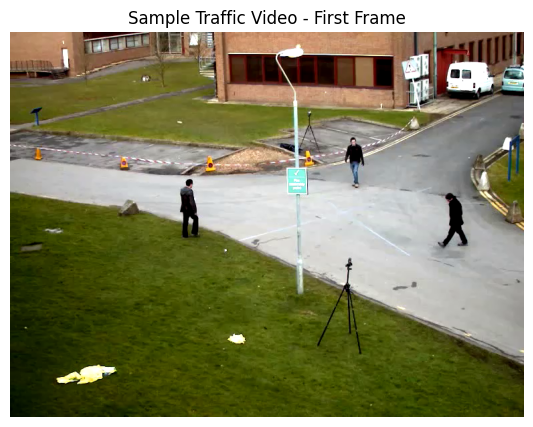

In [3]:

import urllib.request
import os
import cv2

video_url = "https://raw.githubusercontent.com/opencv/opencv_extra/master/testdata/cv/video/768x576.avi"
video_path = "/content/traffic.avi"

urllib.request.urlretrieve(video_url, video_path)

cap = cv2.VideoCapture(video_path)

if cap.isOpened():
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = total_frames / fps if fps > 0 else 0

    print("Video downloaded successfully!")
    print("File:", os.path.basename(video_path))
    print("Total frames:", total_frames)
    print("Original FPS:", round(fps, 2))
    print("Resolution:", f"{width} x {height}")
    print("Duration:", round(duration, 2), "seconds")

    ret, frame = cap.read()
    if ret:
        plt.figure(figsize=(10, 5))
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        plt.title("Sample Traffic Video - First Frame")
        plt.axis("off")
        plt.show()

    cap.release()
else:
    print("Video could not be opened. Please share the error output.")


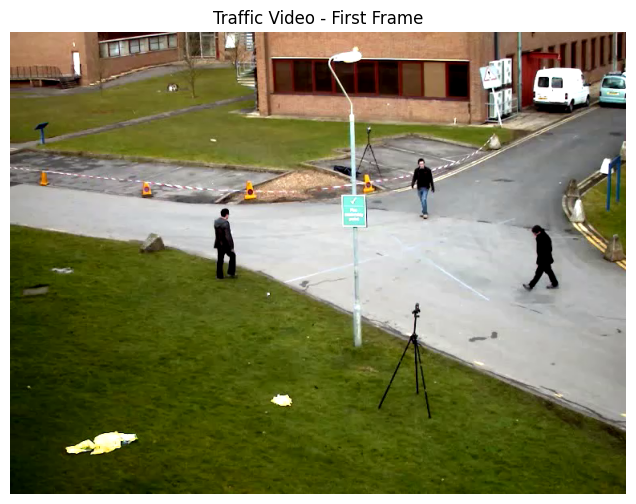

In [4]:

cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

if ret:
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("Traffic Video - First Frame")
    plt.axis("off")
    plt.show()
else:
    print("Could not read the first frame.")

cap.release()


Total contours detected: 1675
Contours within area bounds: 76


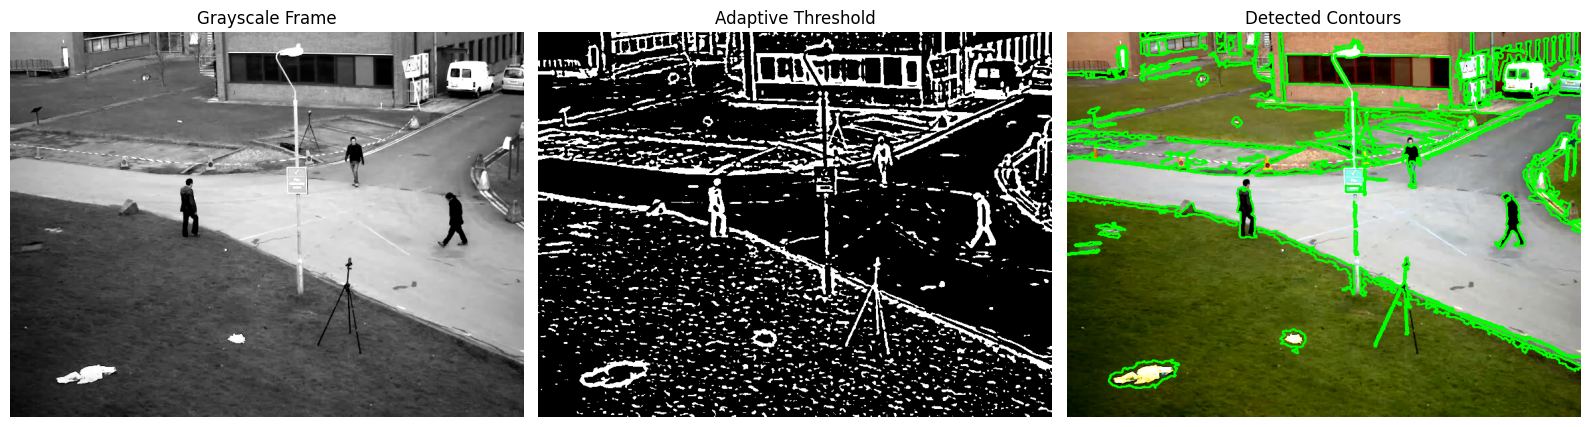

In [5]:

cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()

if ret:
    # Convert frame to grayscale
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Apply Gaussian blur to reduce noise
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Apply adaptive thresholding
    threshold = cv2.adaptiveThreshold(
        blurred,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        21,
        5
    )

    # Extract contours
    contours, _ = cv2.findContours(
        threshold,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Keep contours within selected pixel-area bounds
    min_area = 100
    max_area = 50000

    valid_contours = [
        contour for contour in contours
        if min_area <= cv2.contourArea(contour) <= max_area
    ]

    # Draw detected contours
    output = frame.copy()
    cv2.drawContours(
        output, valid_contours, -1, (0, 255, 0), 2
    )

    print("Total contours detected:", len(contours))
    print("Contours within area bounds:", len(valid_contours))

    # Display processing stages
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    axes[0].imshow(gray, cmap="gray")
    axes[0].set_title("Grayscale Frame")

    axes[1].imshow(threshold, cmap="gray")
    axes[1].set_title("Adaptive Threshold")

    axes[2].imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    axes[2].set_title("Detected Contours")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("Error: Could not read the video frame.")


In [6]:

import cv2
import numpy as np
import pandas as pd
import time
from IPython.display import Video, display

cap = cv2.VideoCapture(video_path)

fps_original = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

output_path = "/content/task4_processed_video.mp4"
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    output_path,
    fourcc,
    fps_original if fps_original > 0 else 25,
    (width, height)
)

records = []
frame_number = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    start_time = time.perf_counter()

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    threshold = cv2.adaptiveThreshold(
        blurred, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        21, 5
    )

    contours, _ = cv2.findContours(
        threshold,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    valid_contours = [
        c for c in contours
        if 100 <= cv2.contourArea(c) <= 50000
    ]

    cv2.drawContours(
        frame, valid_contours, -1, (0, 255, 0), 2
    )

    processing_time = time.perf_counter() - start_time
    processing_ms = processing_time * 1000
    processing_fps = (
        1 / processing_time if processing_time > 0 else 0
    )

    cv2.putText(
        frame, f"Frame: {frame_number + 1}/{total_frames}",
        (15, 30), cv2.FONT_HERSHEY_SIMPLEX,
        0.65, (0, 255, 255), 2
    )
    cv2.putText(
        frame, f"Contours: {len(valid_contours)}",
        (15, 60), cv2.FONT_HERSHEY_SIMPLEX,
        0.65, (0, 255, 255), 2
    )
    cv2.putText(
        frame, f"Processing: {processing_ms:.2f} ms",
        (15, 90), cv2.FONT_HERSHEY_SIMPLEX,
        0.65, (0, 255, 255), 2
    )
    cv2.putText(
        frame, f"Processing FPS: {processing_fps:.2f}",
        (15, 120), cv2.FONT_HERSHEY_SIMPLEX,
        0.65, (0, 255, 255), 2
    )

    out.write(frame)

    records.append({
        "frame": frame_number + 1,
        "total_contours": len(contours),
        "valid_contours": len(valid_contours),
        "processing_time_ms": processing_ms,
        "processing_fps": processing_fps
    })

    frame_number += 1

cap.release()
out.release()

results_df = pd.DataFrame(records)
results_df.to_csv("/content/task4_frame_metrics.csv", index=False)

print("Video processing completed.")
print("Frames processed:", frame_number)
print("Average valid contours:", round(results_df["valid_contours"].mean(), 2))
print("Average processing time (ms):", round(results_df["processing_time_ms"].mean(), 2))
print("Average processing FPS:", round(results_df["processing_fps"].mean(), 2))
print("Processed video:", output_path)
print("Metrics CSV: /content/task4_frame_metrics.csv")


Video processing completed.
Frames processed: 100
Average valid contours: 75.1
Average processing time (ms): 16.59
Average processing FPS: 60.81
Processed video: /content/task4_processed_video.mp4
Metrics CSV: /content/task4_frame_metrics.csv


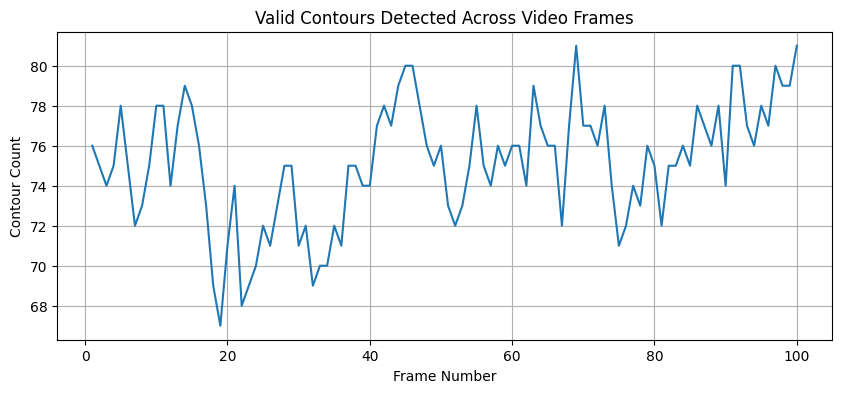

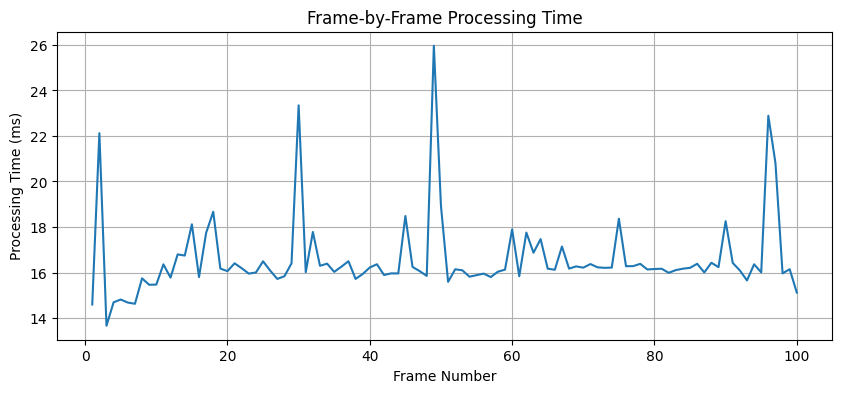

Frame metrics summary:
        frame  total_contours  valid_contours  processing_time_ms  \
count  100.00          100.00          100.00              100.00   
mean    50.50         2152.78           75.10               16.59   
std     29.01          115.52            3.03                1.75   
min      1.00         1674.00           67.00               13.66   
25%     25.75         2163.50           73.00               15.95   
50%     50.50         2182.00           75.00               16.17   
75%     75.25         2203.25           77.00               16.40   
max    100.00         2252.00           81.00               25.96   

       processing_fps  
count          100.00  
mean            60.81  
std              5.07  
min             38.52  
25%             60.97  
50%             61.85  
75%             62.69  
max             73.19  


In [7]:

from IPython.display import Video, display
import matplotlib.pyplot as plt

# Display the processed video
display(Video(output_path, embed=True, width=700))

# Plot contour counts across frames
plt.figure(figsize=(10, 4))
plt.plot(results_df["frame"], results_df["valid_contours"])
plt.title("Valid Contours Detected Across Video Frames")
plt.xlabel("Frame Number")
plt.ylabel("Contour Count")
plt.grid(True)
plt.show()

# Plot processing time across frames
plt.figure(figsize=(10, 4))
plt.plot(results_df["frame"], results_df["processing_time_ms"])
plt.title("Frame-by-Frame Processing Time")
plt.xlabel("Frame Number")
plt.ylabel("Processing Time (ms)")
plt.grid(True)
plt.show()

print("Frame metrics summary:")
print(results_df.describe().round(2))


In [8]:

import cv2
import numpy as np
import pandas as pd
import time
from IPython.display import Video, display

cap = cv2.VideoCapture(video_path)

fps_original = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

tracked_path = "/content/task4_tracked_video.mp4"
out = cv2.VideoWriter(
    tracked_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps_original if fps_original > 0 else 25,
    (width, height)
)

next_id = 0
tracks = {}
max_distance = 50
max_missing_frames = 5
tracking_records = []

frame_no = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    start = time.perf_counter()

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    threshold = cv2.adaptiveThreshold(
        blurred, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV, 21, 5
    )

    contours, _ = cv2.findContours(
        threshold, cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    detections = []

    for c in contours:
        area = cv2.contourArea(c)

        if 100 <= area <= 50000:
            x, y, w, h = cv2.boundingRect(c)
            cx = x + w // 2
            cy = y + h // 2
            detections.append((cx, cy, x, y, w, h))

    # Mark existing tracks as temporarily unmatched
    for track in tracks.values():
        track["missing"] += 1

    # Greedy nearest-centroid matching
    unmatched = set(tracks.keys())

    for det in detections:
        cx, cy, x, y, w, h = det
        best_id = None
        best_distance = max_distance

        for tid in list(unmatched):
            tx, ty = tracks[tid]["centroid"]
            distance = np.hypot(cx - tx, cy - ty)

            if distance < best_distance:
                best_distance = distance
                best_id = tid

        if best_id is None:
            tid = next_id
            next_id += 1
            tracks[tid] = {
                "centroid": (cx, cy),
                "missing": 0
            }
        else:
            tid = best_id
            unmatched.remove(tid)
            tracks[tid]["centroid"] = (cx, cy)
            tracks[tid]["missing"] = 0

        cv2.rectangle(
            frame, (x, y), (x + w, y + h),
            (0, 255, 0), 2
        )
        cv2.putText(
            frame, f"ID {tid}",
            (x, max(20, y - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5, (0, 255, 255), 2
        )

    # Remove tracks not seen for too many frames
    tracks = {
        tid: track for tid, track in tracks.items()
        if track["missing"] <= max_missing_frames
    }

    elapsed = time.perf_counter() - start
    processing_ms = elapsed * 1000
    processing_fps = 1 / elapsed if elapsed > 0 else 0

    cv2.putText(
        frame, f"Frame: {frame_no + 1}/{total_frames}",
        (15, 25), cv2.FONT_HERSHEY_SIMPLEX,
        0.6, (255, 255, 0), 2
    )
    cv2.putText(
        frame, f"Current contours: {len(detections)}",
        (15, 50), cv2.FONT_HERSHEY_SIMPLEX,
        0.6, (255, 255, 0), 2
    )
    cv2.putText(
        frame, f"Active track IDs: {len(tracks)}",
        (15, 75), cv2.FONT_HERSHEY_SIMPLEX,
        0.6, (255, 255, 0), 2
    )
    cv2.putText(
        frame, f"Processing FPS: {processing_fps:.1f}",
        (15, 100), cv2.FONT_HERSHEY_SIMPLEX,
        0.6, (255, 255, 0), 2
    )

    out.write(frame)

    tracking_records.append({
        "frame": frame_no + 1,
        "contour_detections": len(detections),
        "active_tracks": len(tracks),
        "processing_time_ms": processing_ms,
        "processing_fps": processing_fps
    })

    frame_no += 1

cap.release()
out.release()

tracking_df = pd.DataFrame(tracking_records)
tracking_df.to_csv(
    "/content/task4_tracking_metrics.csv", index=False
)

print("Tracking pipeline completed.")
print("Frames processed:", frame_no)
print("Total track IDs created:", next_id)
print("Average active tracks:", round(tracking_df["active_tracks"].mean(), 2))
print("Average processing time (ms):",
      round(tracking_df["processing_time_ms"].mean(), 2))
print("Average processing FPS:",
      round(tracking_df["processing_fps"].mean(), 2))
print("Tracked video:", tracked_path)
print("Tracking metrics CSV: /content/task4_tracking_metrics.csv")


Tracking pipeline completed.
Frames processed: 100
Total track IDs created: 179
Average active tracks: 85.01
Average processing time (ms): 23.22
Average processing FPS: 43.55
Tracked video: /content/task4_tracked_video.mp4
Tracking metrics CSV: /content/task4_tracking_metrics.csv


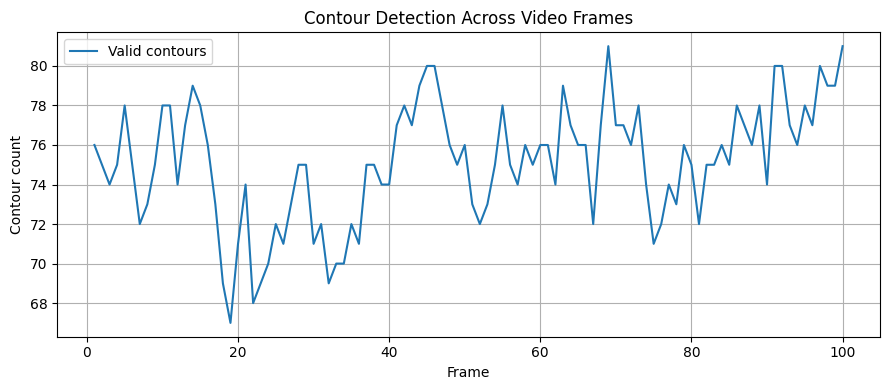

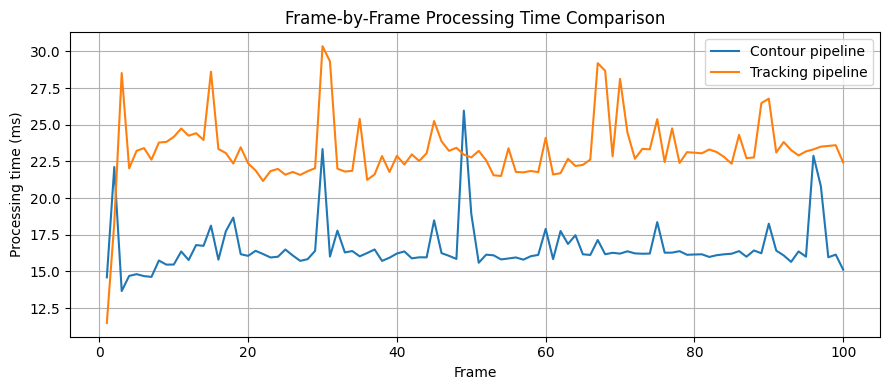

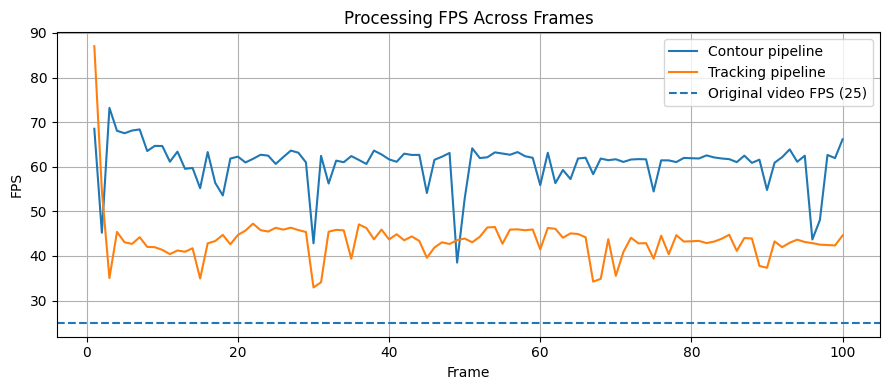

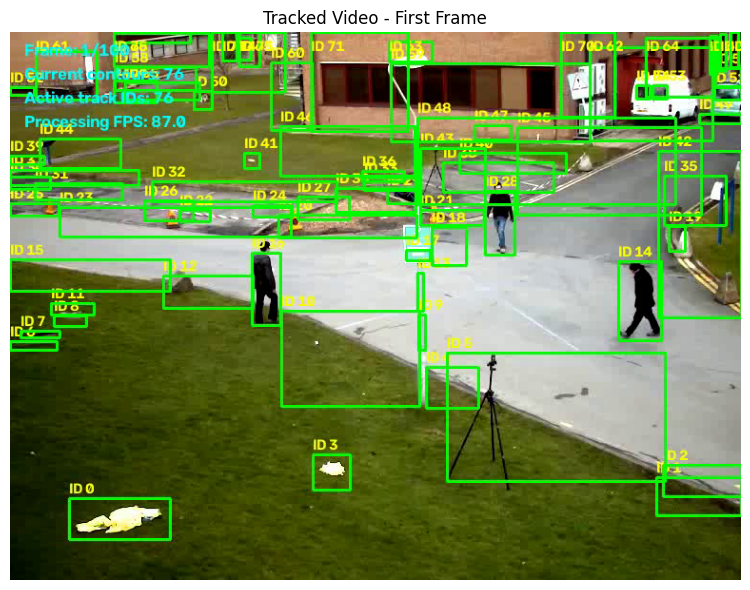

All graphs and preview have been saved.


In [9]:

import matplotlib.pyplot as plt
import cv2
import pandas as pd
from IPython.display import display

# Graph 1: Contour counts across frames
plt.figure(figsize=(9, 4))
plt.plot(
    results_df["frame"],
    results_df["valid_contours"],
    label="Valid contours"
)
plt.title("Contour Detection Across Video Frames")
plt.xlabel("Frame")
plt.ylabel("Contour count")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("/content/task4_contour_counts.png", dpi=150)
plt.show()

# Graph 2: Processing time comparison
plt.figure(figsize=(9, 4))
plt.plot(
    results_df["frame"],
    results_df["processing_time_ms"],
    label="Contour pipeline"
)
plt.plot(
    tracking_df["frame"],
    tracking_df["processing_time_ms"],
    label="Tracking pipeline"
)
plt.title("Frame-by-Frame Processing Time Comparison")
plt.xlabel("Frame")
plt.ylabel("Processing time (ms)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("/content/task4_processing_time.png", dpi=150)
plt.show()

# Graph 3: Processing FPS comparison
plt.figure(figsize=(9, 4))
plt.plot(
    results_df["frame"],
    results_df["processing_fps"],
    label="Contour pipeline"
)
plt.plot(
    tracking_df["frame"],
    tracking_df["processing_fps"],
    label="Tracking pipeline"
)
plt.axhline(
    y=25, linestyle="--",
    label="Original video FPS (25)"
)
plt.title("Processing FPS Across Frames")
plt.xlabel("Frame")
plt.ylabel("FPS")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("/content/task4_fps_comparison.png", dpi=150)
plt.show()

# Inspect a frame from the tracked output video
cap = cv2.VideoCapture(tracked_path)
ret, tracked_frame = cap.read()
cap.release()

if ret:
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(tracked_frame, cv2.COLOR_BGR2RGB))
    plt.title("Tracked Video - First Frame")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig("/content/task4_tracking_preview.png", dpi=150)
    plt.show()
else:
    print("Could not read the tracked video.")

print("All graphs and preview have been saved.")


In [10]:

import os
import zipfile

files_to_package = [
    "/content/task4_processed_video.mp4",
    "/content/task4_tracked_video.mp4",
    "/content/task4_frame_metrics.csv",
    "/content/task4_tracking_metrics.csv",
    "/content/task4_contour_counts.png",
    "/content/task4_processing_time.png",
    "/content/task4_fps_comparison.png",
    "/content/task4_tracking_preview.png"
]

zip_path = "/content/AI_Internship_Task_4_Results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in files_to_package:
        if os.path.exists(file_path):
            zipf.write(file_path, arcname=os.path.basename(file_path))
            print("Added:", os.path.basename(file_path))
        else:
            print("Not found:", os.path.basename(file_path))

print("\nZIP package created:", zip_path)


Added: task4_processed_video.mp4
Added: task4_tracked_video.mp4
Added: task4_frame_metrics.csv
Added: task4_tracking_metrics.csv
Added: task4_contour_counts.png
Added: task4_processing_time.png
Added: task4_fps_comparison.png
Added: task4_tracking_preview.png

ZIP package created: /content/AI_Internship_Task_4_Results.zip


In [11]:

from google.colab import files
files.download("/content/AI_Internship_Task_4_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>